# BÀI THỰC HÀNH TUẦN 4: K-NN & MULTINOMIAL LOGISTIC REGRESSION (SOFTMAX REGRESSION)
- **Họ và tên**: Nguyễn Hải Anh  
- **MSSV**: 24001968  
- **Học phần**: Machine Learning

## Ví dụ A.1: K-NN phân loại nhiều lớp trên dữ liệu 2D tự tạo

Kích thước tập Train: (1200, 2) (1200,)
Kích thước tập Validation: (300, 2) (300,)
Nhãn dự đoán y_pred (20 mẫu đầu): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Nhãn thực tế Y_val   (20 mẫu đầu): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Độ chính xác (Accuracy): 0.98


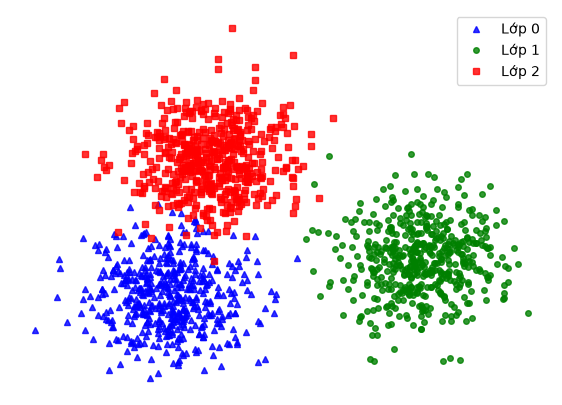

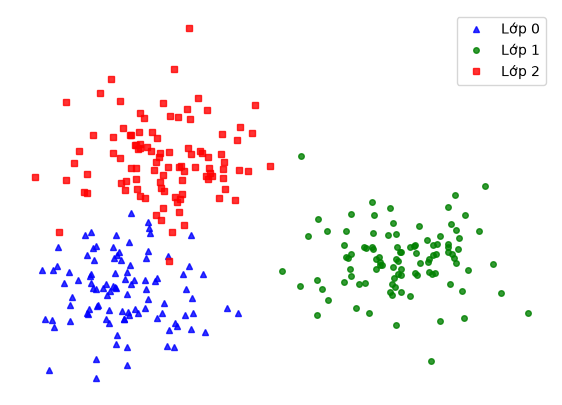

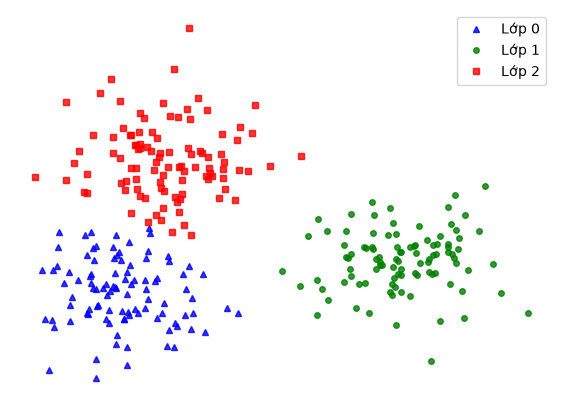

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Các hàm phụ trợ cho K-NN
def distance(array, value):
    array = np.array(array)
    return np.linalg.norm(array - value, ord=2, axis=1)

def find_nearest_index(X_train, x, k):
    return np.argsort(distance(X_train, x))[:k]

def highest_rank(arr):
    count_num = {}
    for i in arr:
        count_num[i] = arr.count(i)
    return max(count_num, key=count_num.get)

# 2. Sinh dữ liệu 2D gồm 3 cụm Gauss
np.random.seed(42)
N = 500
d = 2
C = 3
means = [[2, 2], [8, 3], [3, 6]]
cov = [[1, 0], [0, 1]]

X0 = np.random.multivariate_normal(means[0], cov, N)
X1 = np.random.multivariate_normal(means[1], cov, N)
X2 = np.random.multivariate_normal(means[2], cov, N)

X = np.concatenate((X0, X1, X2), axis=0).T
original_label = np.asarray([0]*N + [1]*N + [2]*N).T

# 3. Hiển thị phân bố dữ liệu ban đầu
def display(X, label):
    X0 = X[:, label == 0]
    X1 = X[:, label == 1]
    X2 = X[:, label == 2]
    plt.figure(figsize=(7, 5))
    plt.plot(X0[0, :], X0[1, :], 'b^', markersize=4, alpha=0.8, label='Lớp 0')
    plt.plot(X1[0, :], X1[1, :], 'go', markersize=4, alpha=0.8, label='Lớp 1')
    plt.plot(X2[0, :], X2[1, :], 'rs', markersize=4, alpha=0.8, label='Lớp 2')
    plt.legend()
    plt.axis('off')
    plt.show()

display(X, original_label)

# 4. Phân chia tập Train (400 mẫu/lớp) và Validation (100 mẫu/lớp)
X_train = np.concatenate((X0[:400], X1[:400], X2[:400]), axis=0)
Y_train = np.concatenate((original_label[:400], original_label[500:900], original_label[1000:1400]), axis=0)

X_val = np.concatenate((X0[400:], X1[400:], X2[400:]), axis=0)
Y_val = np.concatenate((original_label[400:500], original_label[900:1000], original_label[1400:1500]), axis=0)
print('Kích thước tập Train:', X_train.shape, Y_train.shape)
print('Kích thước tập Validation:', X_val.shape, Y_val.shape)

# 5. Dự đoán phân lớp với K = 20
K = 20
y_pred = np.zeros(len(Y_val)).astype(int)
for j in range(len(Y_val)):
    indexes = find_nearest_index(X_train, X_val[j], K)
    y_nearest = [Y_train[indexes[i]] for i in range(K)]
    y_pred[j] = highest_rank(y_nearest)

print('Nhãn dự đoán y_pred (20 mẫu đầu):', y_pred[:20])
print('Nhãn thực tế Y_val   (20 mẫu đầu):', Y_val[:20])
from sklearn.metrics import accuracy_score
print('Độ chính xác (Accuracy):', accuracy_score(Y_val, y_pred))

# Hiển thị trực quan so sánh nhãn thực tế và nhãn dự đoán
display(X_val.T, Y_val)
display(X_val.T, y_pred)


## Ví dụ A.2: Phân loại hoa IRIS bằng K-NN đa chiều

Độ chính xác (Accuracy): 1.0
Độ chính xác chi tiết (Precision macro): 1.0
Ma trận nhầm lẫn (Confusion Matrix):
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


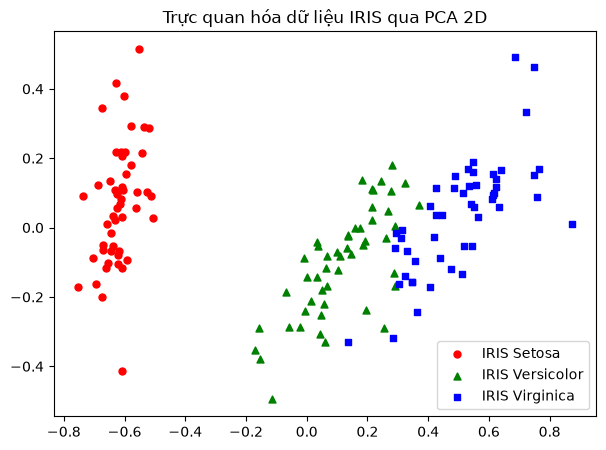

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA as sklearnPCA
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix

# 1. Tải và chuẩn hóa dữ liệu IRIS
iris = datasets.load_iris()
X = iris.data[:, :4]
Y = iris.target

X_norm = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))

# 2. Giảm chiều dữ liệu về 2D bằng PCA để trực quan hóa
pca = sklearnPCA(n_components=2)
transformed = pd.DataFrame(pca.fit_transform(X_norm))

plt.figure(figsize=(7, 5))
plt.scatter(transformed[Y == 0][0], transformed[Y == 0][1], s=25, label='IRIS Setosa', c='red')
plt.scatter(transformed[Y == 1][0], transformed[Y == 1][1], s=25, label='IRIS Versicolor', c='green', marker='^')
plt.scatter(transformed[Y == 2][0], transformed[Y == 2][1], s=25, label='IRIS Virginica', c='blue', marker='s')
plt.legend()
plt.title('Trực quan hóa dữ liệu IRIS qua PCA 2D')
plt.show()

# 3. Chia dữ liệu: 40 mẫu đầu mỗi lớp vào Train, 10 mẫu sau vào Validation
X_train = np.concatenate((X_norm[:40], X_norm[50:90], X_norm[100:140]), axis=0)
Y_train = np.concatenate((Y[:40], Y[50:90], Y[100:140]), axis=0)
X_val = np.concatenate((X_norm[40:50], X_norm[90:100], X_norm[140:150]), axis=0)
Y_val = np.concatenate((Y[40:50], Y[90:100], Y[140:150]), axis=0)

# 4. Dự đoán bằng K-NN (K = 5)
def distance(array, value):
    return np.linalg.norm(array - value, ord=2, axis=1)

def find_nearest_index(X_train, x, k):
    return np.argsort(distance(X_train, x))[:k]

def highest_rank(arr):
    count_num = {}
    for i in arr:
        count_num[i] = arr.count(i)
    return max(count_num, key=count_num.get)

K = 5
y_pred = np.zeros(len(Y_val), dtype=int)
for j in range(len(Y_val)):
    indexes = find_nearest_index(X_train, X_val[j], K)
    y_nearest = [Y_train[indexes[i]] for i in range(K)]
    y_pred[j] = highest_rank(y_nearest)

# 5. Đánh giá kết quả
print('Độ chính xác (Accuracy):', accuracy_score(Y_val, y_pred))
print('Độ chính xác chi tiết (Precision macro):', precision_score(Y_val, y_pred, average='macro'))
print('Ma trận nhầm lẫn (Confusion Matrix):\n', confusion_matrix(Y_val, y_pred))


## Ví dụ B.1: Hồi quy Softmax tự xây dựng từ NumPy trên dữ liệu 2D

Ma trận trọng số tối ưu W:
[[ 6.8466564  -4.91719254 -5.11126197]
 [-0.51938226  1.93457312 -0.30643165]
 [-1.0294131  -0.94459178  1.99542823]]


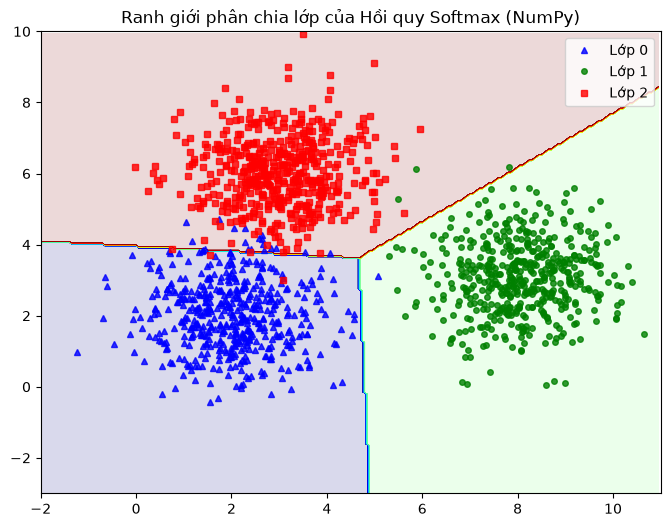

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

# 1. Sinh dữ liệu 2D (3 lớp, N=500 mỗi lớp)
np.random.seed(42)
N = 500
d = 2
C = 3
means = [[2, 2], [8, 3], [3, 6]]
cov = [[1, 0], [0, 1]]

X0 = np.random.multivariate_normal(means[0], cov, N)
X1 = np.random.multivariate_normal(means[1], cov, N)
X2 = np.random.multivariate_normal(means[2], cov, N)

X = np.concatenate((X0, X1, X2), axis=0).T
# Bổ sung hàng 1 cho hệ số bias (x0 = 1)
X = np.concatenate((np.ones((1, 3*N)), X), axis=0)
original_label = np.asarray([0]*N + [1]*N + [2]*N).T

# 2. Xây dựng các hàm cho mô hình Softmax Regression
def convert_labels(y, C=C):
    Y = sparse.coo_matrix((np.ones_like(y), (y, np.arange(len(y)))), shape=(C, len(y))).toarray()
    return Y

def softmax_stable(Z):
    e_Z = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return e_Z / e_Z.sum(axis=0)

def softmax_regression(X, y, W_init, eta, tol=1e-4, max_count=10000):
    W = [W_init]
    C = W_init.shape[1]
    Y = convert_labels(y, C)
    N = X.shape[1]
    d = X.shape[0]
    count = 0
    check_w_after = 20
    while count < max_count:
        mix_id = np.random.permutation(N)
        for i in mix_id:
            xi = X[:, i].reshape(d, 1)
            yi = Y[:, i].reshape(C, 1)
            ai = softmax_stable(np.dot(W[-1].T, xi))
            W_new = W[-1] + eta * xi.dot((yi - ai).T)
            count += 1
            if count % check_w_after == 0:
                if len(W) >= check_w_after and np.linalg.norm(W_new - W[-check_w_after]) < tol:
                    return W
            W.append(W_new)
            if count >= max_count:
                break
    return W

def pred(W, X):
    A = softmax_stable(W.T.dot(X))
    return np.argmax(A, axis=0)

# 3. Huấn luyện mô hình
eta = 0.05
W_init = np.random.randn(X.shape[0], C)
W = softmax_regression(X, original_label, W_init, eta)
print('Ma trận trọng số tối ưu W:')
print(W[-1])

# 4. Trực quan hóa ranh giới phân chia các lớp
xm = np.arange(-2, 11, 0.05)
ym = np.arange(-3, 10, 0.05)
xx, yy = np.meshgrid(xm, ym)
xx1 = xx.ravel().reshape(1, xx.size)
yy1 = yy.ravel().reshape(1, yy.size)
XX = np.concatenate((np.ones((1, xx.size)), xx1, yy1), axis=0)

Z = pred(W[-1], XX)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, 200, cmap='jet', alpha=0.15)
plt.plot(X[1, original_label == 0], X[2, original_label == 0], 'b^', markersize=4, alpha=0.8, label='Lớp 0')
plt.plot(X[1, original_label == 1], X[2, original_label == 1], 'go', markersize=4, alpha=0.8, label='Lớp 1')
plt.plot(X[1, original_label == 2], X[2, original_label == 2], 'rs', markersize=4, alpha=0.8, label='Lớp 2')
plt.xlim(-2, 11)
plt.ylim(-3, 10)
plt.title('Ranh giới phân chia lớp của Hồi quy Softmax (NumPy)')
plt.legend()
plt.show()


## Ví dụ B.2 (Bài tập tự thực hành 1) - Phần a: Hồi quy Softmax tự xây dựng từ NumPy trên dữ liệu hoa IRIS

In [ ]:
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn import datasets
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tải dữ liệu hoa IRIS
iris = datasets.load_iris()
X_raw = iris.data
Y_raw = iris.target

# 2. Phân chia Train:Validation = 4:1 đều theo từng lớp (40 train, 10 val mỗi lớp)
train_idx = []
val_idx = []
for c in range(3):
    c_indices = np.where(Y_raw == c)[0]
    train_idx.extend(c_indices[:40])
    val_idx.extend(c_indices[40:])

X_train_raw = X_raw[train_idx]
Y_train = Y_raw[train_idx]
X_val_raw = X_raw[val_idx]
Y_val = Y_raw[val_idx]

# Chuẩn hóa min-max
min_val = X_train_raw.min(axis=0)
max_val = X_train_raw.max(axis=0)
X_train_norm = (X_train_raw - min_val) / (max_val - min_val)
X_val_norm = (X_val_raw - min_val) / (max_val - min_val)

# Thêm hàng 1 cho bias (dữ liệu dạng d x N)
X_train = np.concatenate((np.ones((len(X_train_norm), 1)), X_train_norm), axis=1).T
X_val = np.concatenate((np.ones((len(X_val_norm), 1)), X_val_norm), axis=1).T

# 3. Các hàm Softmax Regression
def convert_labels(y, C=3):
    return sparse.coo_matrix((np.ones_like(y), (y, np.arange(len(y)))), shape=(C, len(y))).toarray()

def softmax_stable(Z):
    e_Z = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return e_Z / e_Z.sum(axis=0)

def softmax_regression(X, y, W_init, eta, tol=1e-4, max_count=10000):
    W = [W_init]
    C = W_init.shape[1]
    Y = convert_labels(y, C)
    N = X.shape[1]
    d = X.shape[0]
    count = 0
    check_w_after = 20
    while count < max_count:
        mix_id = np.random.permutation(N)
        for i in mix_id:
            xi = X[:, i].reshape(d, 1)
            yi = Y[:, i].reshape(C, 1)
            ai = softmax_stable(np.dot(W[-1].T, xi))
            W_new = W[-1] + eta * xi.dot((yi - ai).T)
            count += 1
            if count % check_w_after == 0:
                if len(W) >= check_w_after and np.linalg.norm(W_new - W[-check_w_after]) < tol:
                    return W
            W.append(W_new)
            if count >= max_count:
                break
    return W

def pred(W, X):
    A = softmax_stable(W.T.dot(X))
    return np.argmax(A, axis=0)

# 4. Huấn luyện và dự đoán
np.random.seed(42)
C = 3
d = X_train.shape[0]
W_init = np.random.randn(d, C)
W = softmax_regression(X_train, Y_train, W_init, eta=0.05, max_count=15000)

y_pred_val = pred(W[-1], X_val)

print('Độ chính xác trên tập Validation:', accuracy_score(Y_val, y_pred_val))
print('Ma trận nhầm lẫn (Confusion Matrix):\n', confusion_matrix(Y_val, y_pred_val))


Độ chính xác trên tập Validation: 1.0
Ma trận nhầm lẫn (Confusion Matrix):
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


## Ví dụ B.2 (Bài tập tự thực hành 1) - Phần b: Hồi quy Softmax trên dữ liệu hoa IRIS bằng Scikit-Learn

In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tải dữ liệu
iris = load_iris()
X = iris.data
Y = iris.target

# 2. Phân chia Train và Test (80:20)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

# 3. Huấn luyện mô hình Logistic Regression đa lớp với thuật toán SAG
lorg = LogisticRegression(solver='sag', max_iter=5000, random_state=42)
lorg.fit(X_train, Y_train)

# 4. Dự đoán và đánh giá
Y_pred = lorg.predict(X_test)
print('Độ chính xác (Accuracy):', accuracy_score(Y_test, Y_pred))
print('Ma trận nhầm lẫn (Confusion Matrix):\n', confusion_matrix(Y_test, Y_pred))


Độ chính xác (Accuracy): 0.9666666666666667
Ma trận nhầm lẫn (Confusion Matrix):
 [[14  0  0]
 [ 0  7  1]
 [ 0  0  8]]


## Ví dụ B.3 (Bài tập tự thực hành 2): Phân loại văn bản 20 Newsgroups bằng Scikit-Learn

In [ ]:
import numpy as np
from sklearn.datasets import fetch_20newsgroups_vectorized
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tải dữ liệu 20 Newsgroups đã vector hóa
X, y = fetch_20newsgroups_vectorized(subset='all', return_X_y=True)

# Lấy 5000 mẫu để tối ưu thời gian huấn luyện
n_samples = 5000
X = X[:n_samples]
y = y[:n_samples]

# 2. Phân chia Train và Test theo tỷ lệ 75:25 có phân tầng (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print('Số lượng mẫu train:', X_train.shape[0], 'Số đặc trưng:', X_train.shape[1])
print('Số lượng mẫu test:', X_test.shape[0])
print('Số lượng nhóm chủ đề (classes):', np.unique(y).shape[0])

# 3. Huấn luyện mô hình Logistic Regression
clf = LogisticRegression(max_iter=100, random_state=42)
clf.fit(X_train, y_train)

# 4. Dự đoán và đánh giá
y_pred = clf.predict(X_test)
print('Độ chính xác (Accuracy):', accuracy_score(y_test, y_pred))
print('Kích thước ma trận nhầm lẫn:', confusion_matrix(y_test, y_pred).shape)
print('Ma trận nhầm lẫn (Confusion Matrix):\n', confusion_matrix(y_test, y_pred))


Số lượng mẫu train: 3750 Số đặc trưng: 130107
Số lượng mẫu test: 1250
Số lượng nhóm chủ đề (classes): 20
Độ chính xác (Accuracy): 0.6912
Kích thước ma trận nhầm lẫn: (20, 20)
Ma trận nhầm lẫn (Confusion Matrix):
 [[35  0  0  0  0  0  0  0  2  1  1  0  0  1  0  9  2  3  1  0]
 [ 0 45  3  1  4  2  1  1  1  0  0  0  0  4  1  2  0  3  0  0]
 [ 0  4 43  9  0  4  3  0  1  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  6  5 43  2  2  2  1  0  0  0  0  1  0  1  0  1  0  0  0]
 [ 0  2  2  7 45  2  2  1  0  0  0  0  1  1  1  0  1  0  0  0]
 [ 0  8  4  2  1 35  2  0  0  1  1  1  3  0  0  1  0  0  0  0]
 [ 1  1  1  2  2  1 47  2  0  0  1  0  0  1  2  0  1  0  0  0]
 [ 0  3  1  0  0  1  0 47  5  0  2  0  4  0  0  0  1  3  1  0]
 [ 0  1  0  1  2  0  2  4 48  0  0  0  0  2  0  2  1  1  0  0]
 [ 0  0  1  0  1  0  2  1  3 50  8  0  0  1  0  0  0  0  1  0]
 [ 0  0  0  0  0  0  2  0  1  9 52  0  0  0  0  1  0  0  0  0]
 [ 0  1  0  0  0  1  1  1  0  0  1 63  1  0  1  0  1  0  1  0]
 [ 2  5  2  2  5  4  4  4  2  2

## Ví dụ B.4 (Bài tập tự thực hành 3): Phân loại các loại kính (glass.csv)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# 1. Đọc dữ liệu từ file glass.csv
glass_df = pd.read_csv('glass.csv', header=None, names=['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'])

print('Thông tin dữ liệu Glass:')
print(glass_df.info())
print('\nCác lớp kính trong dữ liệu:', np.sort(glass_df['Type'].unique()))
print('\nSố lượng mẫu theo từng loại kính:\n', glass_df['Type'].value_counts().sort_index())

# 2. Phân tách đặc trưng và nhãn
X = glass_df[['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']]
y = glass_df['Type']

# 3. Phân chia tập Train và Test (75:25)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Chuẩn hóa đặc trưng
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Huấn luyện mô hình Hồi quy Logistic đa lớp
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Dự đoán và đánh giá
y_pred = model.predict(X_test_scaled)
print('Độ chính xác (Accuracy):', accuracy_score(y_test, y_pred))
print('Độ chính xác Precision (macro):', precision_score(y_test, y_pred, average='macro', zero_division=0))
print('Độ nhạy Recall (macro):', recall_score(y_test, y_pred, average='macro', zero_division=0))
print('Ma trận nhầm lẫn (Confusion Matrix):\n', confusion_matrix(y_test, y_pred))


Thông tin dữ liệu Glass:
<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB
None

Các lớp kính trong dữ liệu: [1 2 3 5 6 7]

Số lượng mẫu theo từng loại kính:
 Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64
Độ chính xác (Accuracy): 0.7037037037037037
Độ chính xác Precision (macro): 0.6453703703703703
Độ nhạy Recall (macro): 0.7256335282651071
Ma trận nhầm lẫn (Confusion Matrix):
 [[13  5  0  0  0  0]
 [ 4 12  1  0  1  1]
 [ 3 

## Ví dụ 4: Phân loại chữ số viết tay MNIST bằng Softmax Regression tự xây dựng

Kích thước dữ liệu Train: (5000, 784) (5000,)
Kích thước dữ liệu Test: (2000, 784) (2000,)
epoch 0 - cost 0.7743
epoch 1 - cost 0.5831
epoch 2 - cost 0.5027
epoch 3 - cost 0.4591
epoch 4 - cost 0.4278
epoch 5 - cost 0.4035
epoch 6 - cost 0.3857
epoch 7 - cost 0.3711
epoch 8 - cost 0.3590
epoch 9 - cost 0.3490
Độ chính xác trên tập Train (Scratch): 0.9088
Độ chính xác trên tập Test (Scratch): 0.902


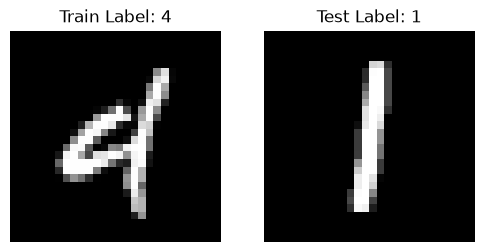

In [ ]:
import os
import gzip
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import accuracy_score

# 1. Phương thức giải nén và đọc dữ liệu MNIST từ các file .gz
def get_mnist_data(images_path, labels_path, num_images, shuffle=False, _is=True, image_size=28):
    f_images = gzip.open(images_path, 'r')
    f_images.read(16)
    real_num = num_images if not shuffle else (60000 if _is else 10000)
    buf_images = f_images.read(image_size * image_size * real_num)
    images = np.frombuffer(buf_images, dtype=np.uint8).astype(np.float32)
    images = images.reshape(real_num, image_size, image_size)
    
    f_labels = gzip.open(labels_path, 'r')
    f_labels.read(8)
    labels = np.zeros((real_num)).astype(np.int64)
    for i in range(real_num):
        buf_labels = f_labels.read(1)
        labels[i] = np.frombuffer(buf_labels, dtype=np.uint8).astype(np.int64)[0]
        
    if shuffle:
        np.random.seed(42)
        rand_id = np.random.randint(real_num, size=num_images)
        images = images[rand_id, :]
        labels = labels[rand_id]
        
    images = images.reshape(num_images, image_size * image_size)
    return images, labels

# Đường dẫn file
train_images_path = 'train-images-idx3-ubyte.gz'
train_labels_path = 'train-labels-idx1-ubyte.gz'
test_images_path = 't10k-images-idx3-ubyte.gz'
test_labels_path = 't10k-labels-idx1-ubyte.gz'

# Đọc 5000 ảnh train và 2000 ảnh test
train_images, train_labels = get_mnist_data(train_images_path, train_labels_path, 5000, shuffle=True)
test_images, test_labels = get_mnist_data(test_images_path, test_labels_path, 2000, _is=False, shuffle=True)
print('Kích thước dữ liệu Train:', train_images.shape, train_labels.shape)
print('Kích thước dữ liệu Test:', test_images.shape, test_labels.shape)

# 2. Hiển thị thử mẫu ảnh
fig, axarr = plt.subplots(1, 2, figsize=(6, 3))
axarr[0].imshow(train_images[0].reshape(28, 28), cmap='gray')
axarr[0].set_title(f'Train Label: {train_labels[0]}')
axarr[0].axis('off')
axarr[1].imshow(test_images[0].reshape(28, 28), cmap='gray')
axarr[1].set_title(f'Test Label: {test_labels[0]}')
axarr[1].axis('off')
plt.show()

# 3. Chuẩn bị ma trận dữ liệu (chuẩn hóa pixel về [0, 1] và thêm hàng 1 cho bias)
X_train = np.concatenate((np.ones((1, train_images.shape[0])), (train_images / 255.0).T), axis=0)
X_test = np.concatenate((np.ones((1, test_images.shape[0])), (test_images / 255.0).T), axis=0)

def convert_labels(y, C=10):
    return sparse.coo_matrix((np.ones_like(y), (y, np.arange(len(y)))), shape=(C, len(y))).toarray()

Y_train = convert_labels(train_labels, 10)

def softmax_stable(Z):
    e_Z = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return e_Z / e_Z.sum(axis=0)

def pred(W, X):
    A = softmax_stable(W.T.dot(X))
    return np.argmax(A, axis=0)

def _softmax_regression(X, Y, theta, iterations=10, learning_rate=1e-3):
    _theta = theta.copy()
    d, N = X.shape
    C = Y.shape[0]
    for iter_ in range(iterations):
        shuffle_index = np.random.permutation(N)
        for i in shuffle_index:
            xi = X[:, i].reshape(d, 1)
            yi = Y[:, i].reshape(C, 1)
            ai = softmax_stable(np.dot(_theta.T, xi))
            _theta += learning_rate * xi.dot((yi - ai).T)
        A = softmax_stable(np.dot(_theta.T, X))
        cost = -np.sum(Y * np.log(A + 1e-12)) / N
        print(f'epoch {iter_} - cost {cost:.4f}')
    return _theta

# 4. Huấn luyện mô hình Softmax Regression
theta_init = np.zeros((X_train.shape[0], 10))
opt_theta = _softmax_regression(X_train, Y_train, theta_init, iterations=10, learning_rate=1e-3)

# 5. Đánh giá độ chính xác
train_acc = accuracy_score(train_labels, pred(opt_theta, X_train))
test_acc = accuracy_score(test_labels, pred(opt_theta, X_test))
print('Độ chính xác trên tập Train (Scratch):', train_acc)
print('Độ chính xác trên tập Test (Scratch):', test_acc)


## Bài tập tự thực hành 4 - Yêu cầu 1: Trực quan hóa dữ liệu MNIST bằng PCA về 2 chiều

Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.0982293  0.07246957]


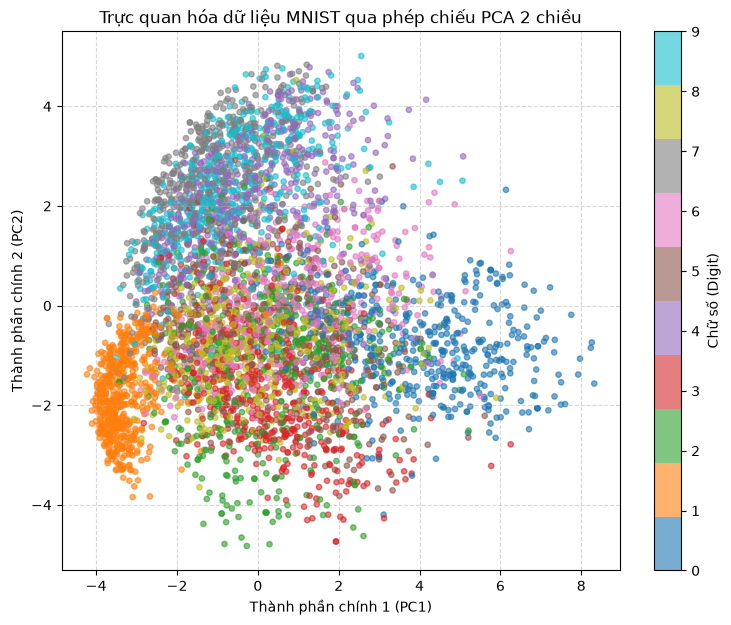

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Áp dụng PCA đưa dữ liệu ảnh MNIST về 2 chiều
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(train_images / 255.0)

# 2. Vẽ biểu đồ phân bố 2D của các chữ số 0 đến 9
plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=train_labels, cmap='tab10', alpha=0.6, s=15)
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label('Chữ số (Digit)')
plt.title('Trực quan hóa dữ liệu MNIST qua phép chiếu PCA 2 chiều')
plt.xlabel('Thành phần chính 1 (PC1)')
plt.ylabel('Thành phần chính 2 (PC2)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print('Tỷ lệ phương sai giải thích bởi 2 thành phần chính:', pca.explained_variance_ratio_)


## Bài tập tự thực hành 4 - Yêu cầu 2: Huấn luyện phân loại MNIST bằng Scikit-Learn LogisticRegression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Huấn luyện mô hình LogisticRegression của Scikit-Learn trên dữ liệu MNIST
clf_mnist = LogisticRegression(solver='lbfgs', max_iter=200, random_state=42)
clf_mnist.fit(train_images / 255.0, train_labels)

# 2. Đánh giá kết quả trên tập Train và Test
y_pred_train = clf_mnist.predict(train_images / 255.0)
y_pred_test = clf_mnist.predict(test_images / 255.0)

print('Độ chính xác trên tập Train (Scikit-Learn):', accuracy_score(train_labels, y_pred_train))
print('Độ chính xác trên tập Test (Scikit-Learn):', accuracy_score(test_labels, y_pred_test))
print('\nMa trận nhầm lẫn trên tập Test (Confusion Matrix):\n', confusion_matrix(test_labels, y_pred_test))


Độ chính xác trên tập Train (Scikit-Learn): 0.987
Độ chính xác trên tập Test (Scikit-Learn): 0.905

Ma trận nhầm lẫn trên tập Test (Confusion Matrix):
 [[203   0   1   0   0   1   4   0   1   0]
 [  0 241   2   1   0   1   3   0   1   0]
 [  3   4 169   4   1   1   0   3   5   1]
 [  0   0   6 190   0   5   0   4   8   4]
 [  0   2   0   2 172   0   2   0   2  11]
 [  5   1   2  11   2 140   2   3   7   2]
 [  1   0   2   2   3   1 185   0   0   0]
 [  0   1   2   2   1   0   0 170   0   8]
 [  1   0   4   5   2   6   4   0 168   3]
 [  1   0   2   1   7   1   1   9   2 172]]
